# Dichotic right

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('dichotic_right')

7 of 7 results this notebook reads are not on the cluster yet; asking the cluster for them.
Submitted job 9239211 for dichotic_right. Follow it with cluster_queue(); the cluster also emails when it ends.
Waiting for job 9239211 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  22:21  9239211 pending  (0 min so far)
  22:27  9239211 running  (6 min so far)
  23:07  9239211 completing  (46 min so far)
Job 9239211 is done: all 7 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-dichotic_right-9239211.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:29:51 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:30:35 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
=== dichotic_ri

## Dichotic Right

In [5]:
# Loaded once here, reused by every unique-contribution/STRF/peak/
# waveform/attention-effect cell in this section - each one just
# reads a different predictor column out of this same fit instead
# of re-running the (expensive) TRF fit on FULL_BASE again.
data_full = load_trfs_saved(FULL_BASE, 'dichotic-right')

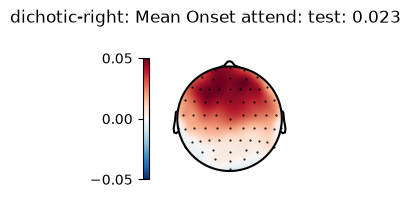

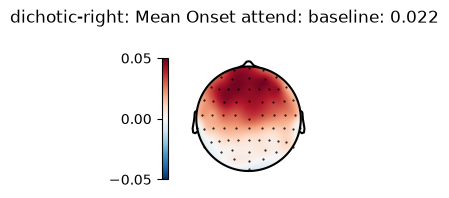

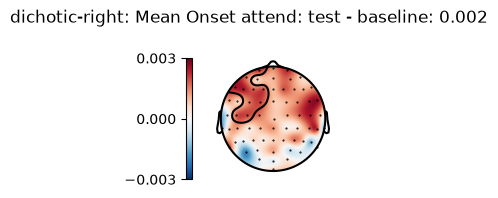

In [6]:
# Onset attend unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(ATTEND), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Onset attend', 'dichotic-right', onset(ATTEND))

In [7]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 3 clusters, p = .012>

Onset attend (dichotic-right): ROI unique contribution t(12) = 2.489, p = 0.0142


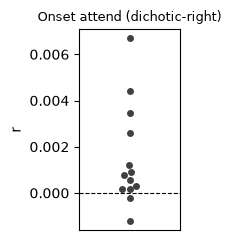

In [8]:
p = show_subject_swarm(diff, 'Onset attend', 'dichotic-right')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


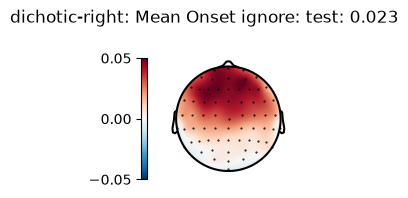

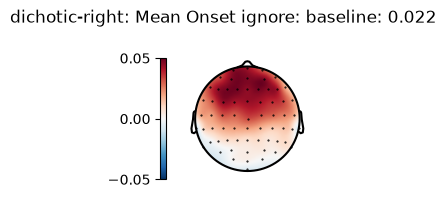

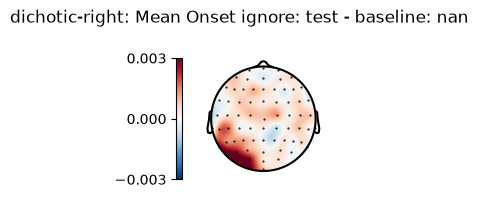

In [9]:
# Onset ignore unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(IGNORE), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Onset ignore', 'dichotic-right', onset(IGNORE))

In [10]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 4 clusters, p = .134>

Onset ignore (dichotic-right): ROI unique contribution t(12) = 0.983, p = 0.1726


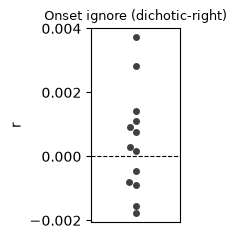

In [11]:
p = show_subject_swarm(diff, 'Onset ignore', 'dichotic-right')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


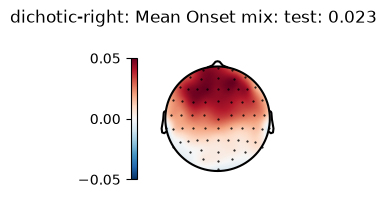

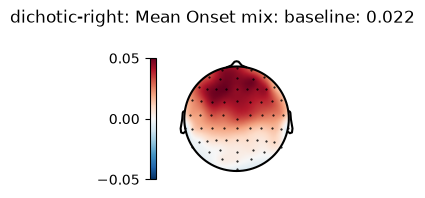

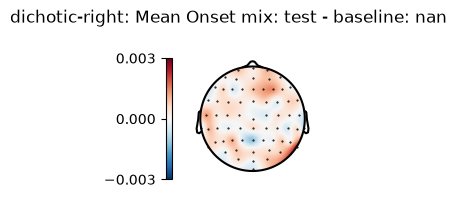

In [12]:
# Onset mix unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(MIX), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Onset mix', 'dichotic-right', onset(MIX))

In [13]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 2 clusters, p = .562>

Onset mix (dichotic-right): ROI unique contribution t(12) = 0.613, p = 0.2756


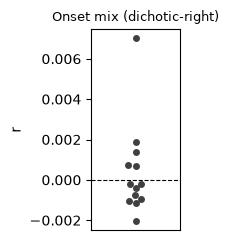

In [14]:
p = show_subject_swarm(diff, 'Onset mix', 'dichotic-right')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


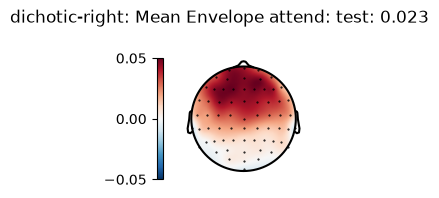

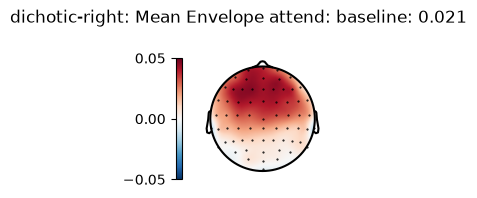

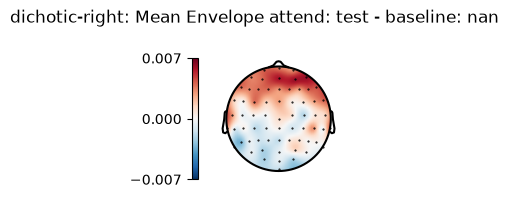

In [15]:
# Envelope attend unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(ATTEND), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Envelope attend', 'dichotic-right', envelope(ATTEND))

In [16]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .185>

Envelope attend (dichotic-right): ROI unique contribution t(12) = 1.148, p = 0.1367


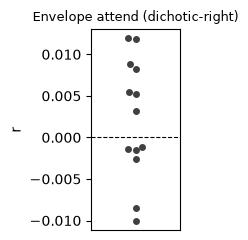

In [17]:
p = show_subject_swarm(diff, 'Envelope attend', 'dichotic-right')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


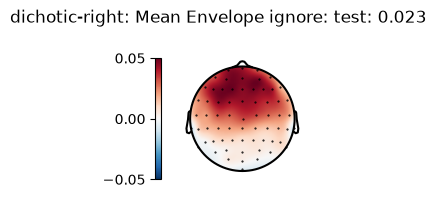

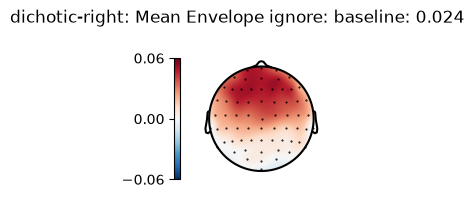

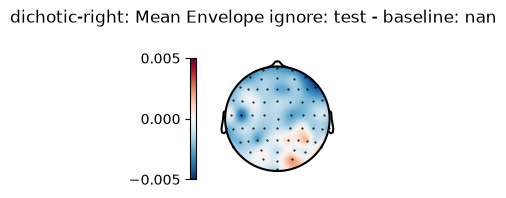

In [18]:
# Envelope ignore unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(IGNORE), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'dichotic-right', envelope(IGNORE))

In [19]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, no clusters>

Envelope ignore (dichotic-right): ROI unique contribution t(12) = -1.537, p = 0.9249


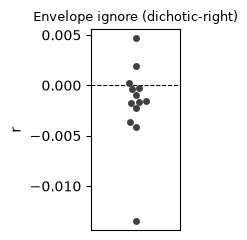

In [20]:
p = show_subject_swarm(diff, 'Envelope ignore', 'dichotic-right')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


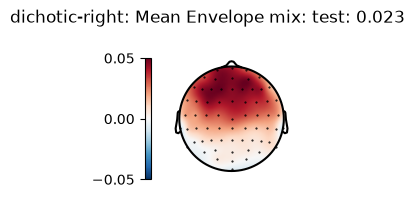

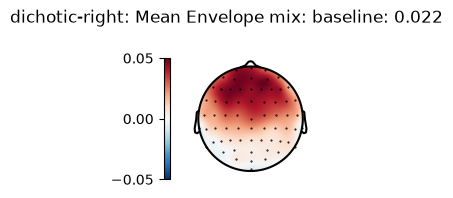

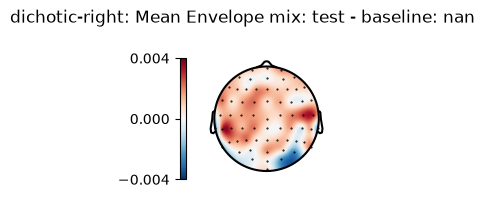

In [21]:
# Envelope mix unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(MIX), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Envelope mix', 'dichotic-right', envelope(MIX))

In [22]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 4 clusters, p = .249>

Envelope mix (dichotic-right): ROI unique contribution t(12) = 0.993, p = 0.1701


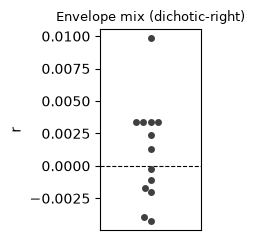

In [23]:
p = show_subject_swarm(diff, 'Envelope mix', 'dichotic-right')

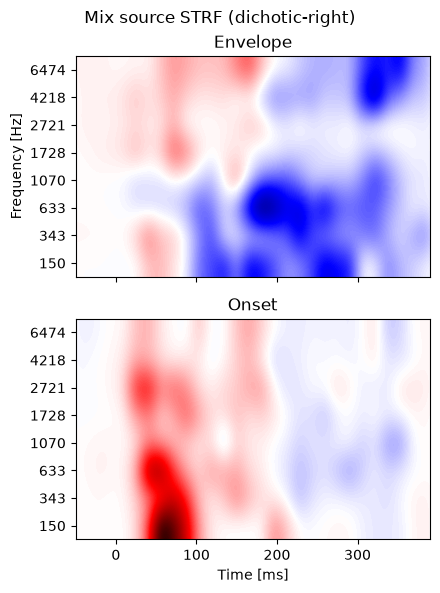

In [24]:
# Mix source STRF: envelope + onset (dichotic-right)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (dichotic-right)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

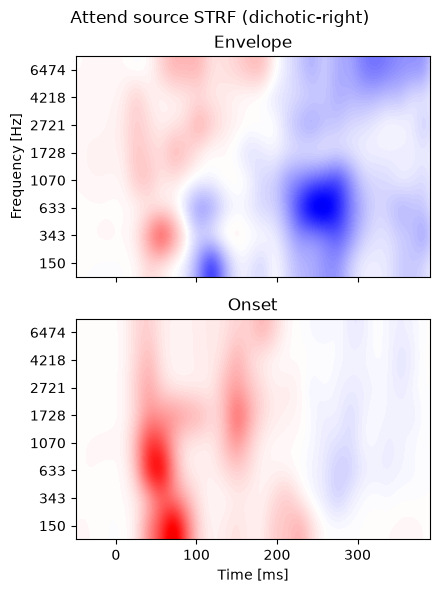

In [25]:
# Attend source STRF: envelope + onset (dichotic-right)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (dichotic-right)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

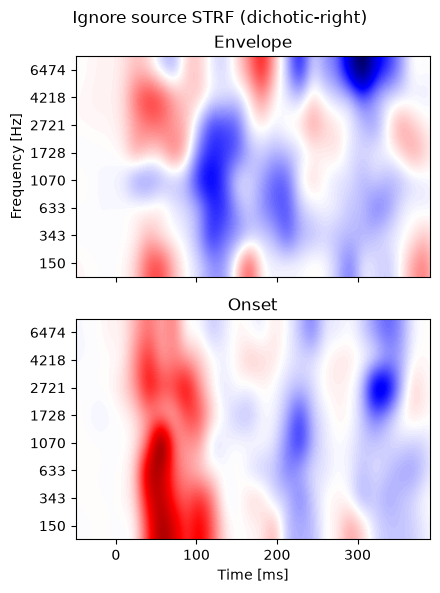

In [26]:
# Ignore source STRF: envelope + onset (dichotic-right)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (dichotic-right)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [27]:
# Onset attend peak amplitude & timing (dichotic-right)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (dichotic-right) positive peak: 53 ms, amp 0.004056
Onset attend (dichotic-right) negative peak: 117 ms, amp 7.259e-05


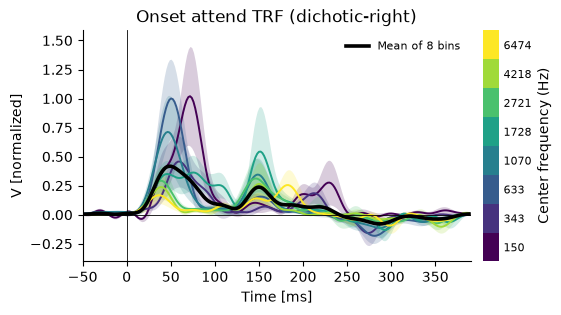

In [28]:
# Onset attend TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (dichotic-right)')

In [29]:
# Onset ignore peak amplitude & timing (dichotic-right)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (dichotic-right) positive peak: 61 ms, amp 0.002512
Onset ignore (dichotic-right) negative peak: 141 ms, amp -0.000389


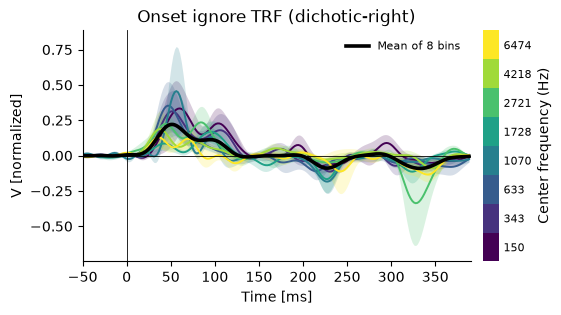

In [30]:
# Onset ignore TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (dichotic-right)')

In [31]:
# Onset mix peak amplitude & timing (dichotic-right)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (dichotic-right) positive peak: 59 ms, amp 0.003559
Onset mix (dichotic-right) negative peak: 189 ms, amp -3.909e-06


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


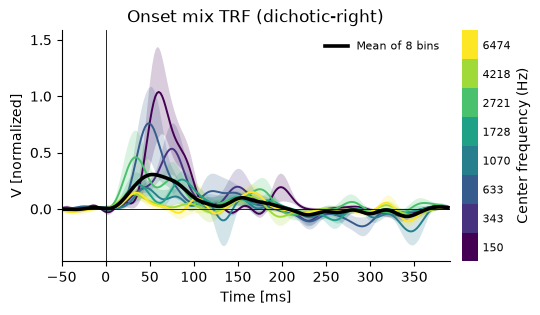

In [32]:
# Onset mix TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (dichotic-right)')

In [33]:
# Envelope attend peak amplitude & timing (dichotic-right)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (dichotic-right) positive peak: 53 ms, amp 0.001748
Envelope attend (dichotic-right) negative peak: 121 ms, amp -0.001331


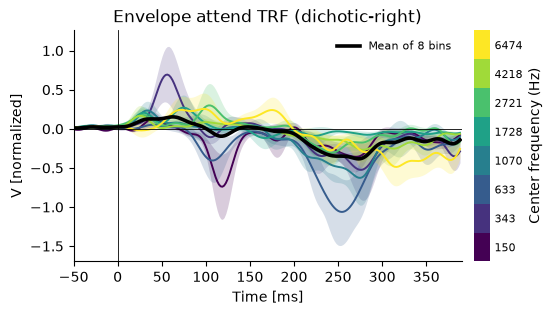

In [34]:
# Envelope attend TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (dichotic-right)')

In [35]:
# Envelope ignore peak amplitude & timing (dichotic-right)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (dichotic-right) positive peak: 52 ms, amp 0.0007013
Envelope ignore (dichotic-right) negative peak: 122 ms, amp -0.001431


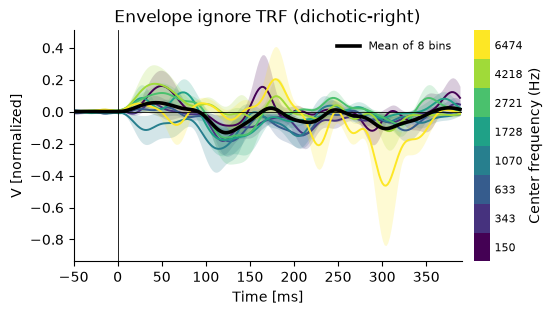

In [36]:
# Envelope ignore TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (dichotic-right)')

In [37]:
# Envelope mix peak amplitude & timing (dichotic-right)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (dichotic-right) positive peak: 73 ms, amp 0.001015
Envelope mix (dichotic-right) negative peak: 188 ms, amp -0.001977


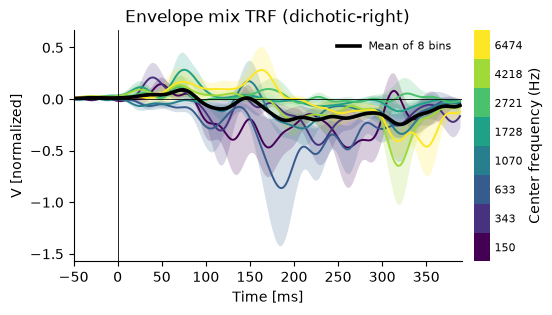

In [38]:
# Envelope mix TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (dichotic-right)')

In [39]:
# Onset peak comparison across mix, attend, and ignore (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (mix) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


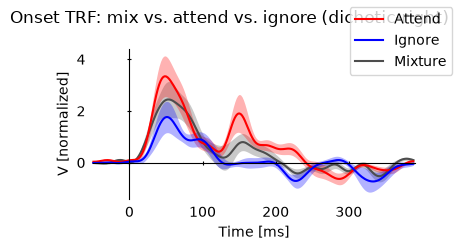

In [40]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (dichotic-right)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [41]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 78      0.001891
02        mix                 72      0.004169
03        mix                 41      0.001378
04        mix                 60      0.001109
05        mix                 52      0.006518
06        mix                 41     0.0007583
07        mix                 50      0.004679
08        mix                 43      0.004911
09        mix                 72      0.003722
10        mix                 56      0.008262
11        mix                 41      0.003377
12        mix                 78      0.005367
13        mix                 78      0.000124
01        attend              41      0.001214
02        attend              50      0.003125
03        attend              56     0.0005381
04        attend              58      0.002087
05        attend              41      0.008574
06        attend              41      0.001157
07        attend              41      0.00222

In [42]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = 1.29 p = .222,t12 = -0.91 p = .380
attend,,t12 = -1.77 p = .102


,attend,ignore
mix,t12 = 12.06*** p < .001,t12 = 10.07*** p < .001
attend,,t12 = -3.37** p = .006


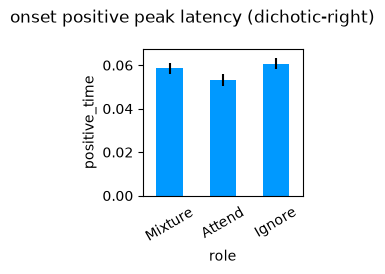

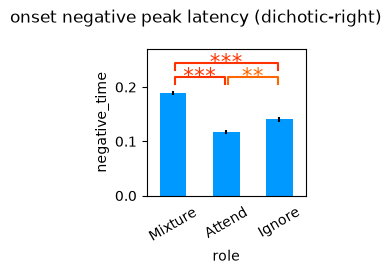

In [43]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (dichotic-right)')
p.set_xtick_rotation(30)

In [44]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -0.55 p = .590,t12 = 1.62 p = .130
attend,,t12 = 1.62 p = .131


,attend,ignore
mix,t12 = -0.24 p = .816,t12 = 2.05 p = .062
attend,,t12 = 1.77 p = .101


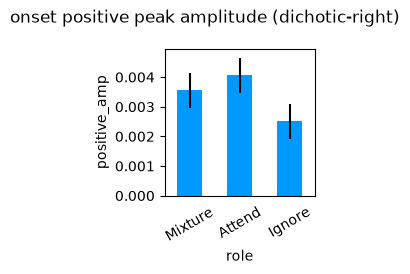

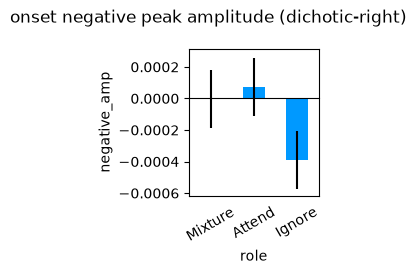

In [45]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)

In [46]:
# Envelope peak comparison across mix, attend, and ignore (dichotic-right)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

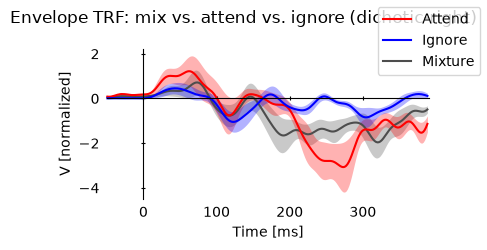

In [47]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (dichotic-right)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [48]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 70      0.007055
02        mix                 62     7.236e-05
03        mix                 82       0.00251
04        mix                 74     0.0009353
05        mix                 80    -6.281e-05
06        mix                 95     0.0003084
07        mix                 50     0.0003271
08        mix                 86      0.001489
09        mix                 70     0.0008424
10        mix                 50     6.168e-05
11        mix                 50    -0.0004453
12        mix                 80     -0.000272
13        mix                 97     0.0003727
01        attend              74       0.01027
02        attend              58     0.0002267
03        attend              62     0.0008942
04        attend              70      0.001026
05        attend              41     -0.000139
06        attend              52      0.002255
07        attend              46     0.000890

In [49]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = 3.53** p = .004,t12 = 3.24** p = .007
attend,,t12 = 0.17 p = .868


,attend,ignore
mix,t12 = 12.55*** p < .001,t12 = 11.95*** p < .001
attend,,t12 = -0.05 p = .960


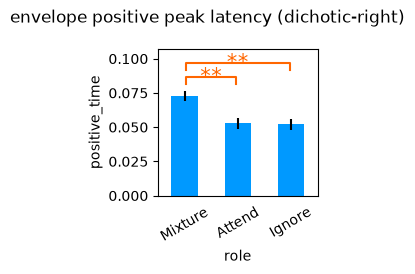

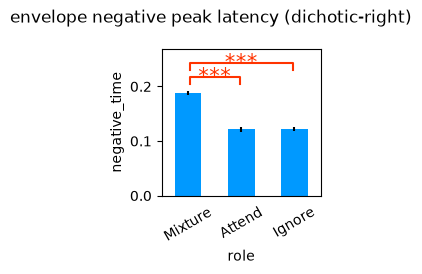

In [50]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (dichotic-right)')
p.set_xtick_rotation(30)

In [51]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -2.13 p = .054,t12 = 0.53 p = .607
attend,,t12 = 1.23 p = .243


,attend,ignore
mix,t12 = -0.69 p = .501,t12 = -0.65 p = .529
attend,,t12 = 0.11 p = .914


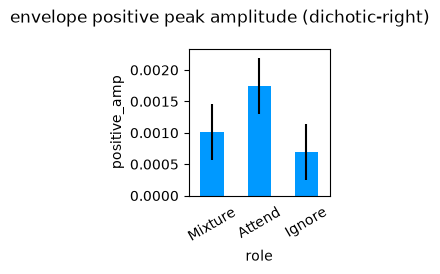

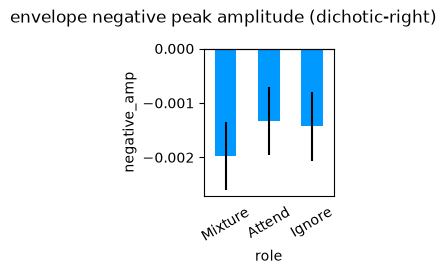

In [52]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)

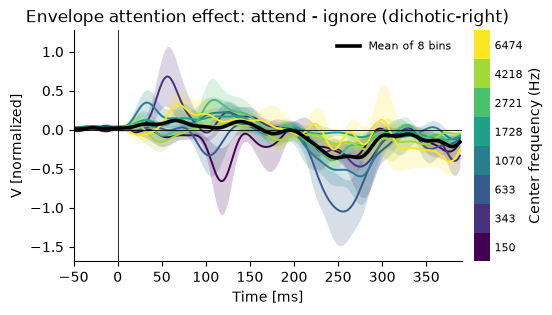

In [53]:
# Envelope attention effect: attend - ignore (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (dichotic-right)', subtract='bg_gammatone_8')

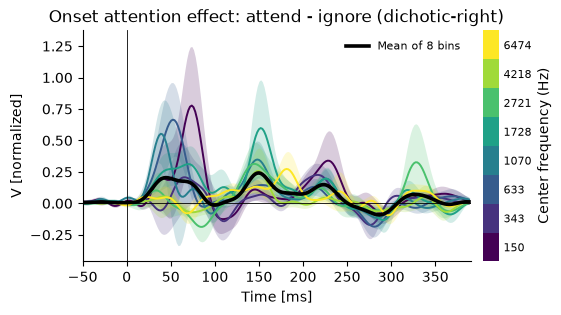

In [54]:
# Onset attention effect: attend - ignore (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (dichotic-right)', subtract='bg_gammatone_on_8')